# String Matching Algorithms and Applications

In [ ]:
import csv
import json
import os
import random
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd

RAW_DIR = next((d for d in ("/content", "raw", ".")
                if os.path.exists(os.path.join(d, "human.txt"))), "raw")

SEED = 42
REPEATS = 3
MAX_N = 10**6
QUADRATIC_LIMIT = 10**5
PATTERN_LENGTHS = [5, 50, 500]

rng = random.Random(SEED)
plt.rcParams["figure.figsize"] = (7, 5)
print("RAW_DIR =", RAW_DIR, "| contents:", sorted(os.listdir(RAW_DIR)) if os.path.isdir(RAW_DIR) else "MISSING")

RAW_DIR = /content | contents: ['.config', 'gutenberg_metadata.csv', 'human.txt', 'sample_data']


---
## Chapter 2 — Algorithmic Analysis

### 2.4 Brute-Force (baseline)

```
BRUTE-FORCE(T, P)
  n <- length(T);  m <- length(P)
  result <- empty list
  for i <- 0 to n - m
      j <- 0
      while j < m and T[i + j] = P[j]
          j <- j + 1
      if j = m
          append i to result
  return result
```

The pattern is aligned at every shift and compared character by character; on a mismatch the alignment advances by exactly one and comparison restarts from `P[0]`.

Best case Θ(n) when the first character of `P` rarely occurs in `T`. Worst case Θ(n·m) on periodic text. Auxiliary space O(1).

In [ ]:
def brute_force(t, p):
    n, m = len(t), len(p)
    positions = []
    comparisons = 0
    for i in range(n - m + 1):
        j = 0
        while j < m:
            comparisons += 1
            if t[i + j] != p[j]:
                break
            j += 1
        if j == m:
            positions.append(i)
    return positions, {"comparisons": comparisons}

### 2.2 Knuth-Morris-Pratt

```
BUILD-PI(P)
  m <- length(P)
  pi[0..m-1] <- 0
  j <- 0
  for i <- 1 to m - 1
      while j > 0 and P[i] != P[j]
          j <- pi[j - 1]
      if P[i] = P[j]
          j <- j + 1
      pi[i] <- j
  return pi

KMP-SEARCH(T, P)
  pi <- BUILD-PI(P)
  n <- length(T);  m <- length(P)
  result <- empty list
  j <- 0
  for i <- 0 to n - 1
      while j > 0 and T[i] != P[j]
          j <- pi[j - 1]
      if T[i] = P[j]
          j <- j + 1
      if j = m
          append i - m + 1 to result
          j <- pi[j - 1]
  return result
```

`pi[i]` holds the length of the longest proper border of `P[0..i]`. The text pointer never moves backward, so KMP works on streams.

Amortised argument: `j` grows by at most one per iteration of the outer loop, so across the whole scan it can decrease at most `n` times. Preprocessing Θ(m), search Θ(n), total Θ(n + m) in every case. Auxiliary space Θ(m).

In [ ]:
def build_pi(p):
    m = len(p)
    pi = [0] * m
    comparisons = 0
    j = 0
    for i in range(1, m):
        while j > 0 and p[i] != p[j]:
            comparisons += 1
            j = pi[j - 1]
        comparisons += 1
        if p[i] == p[j]:
            j += 1
        pi[i] = j
    return pi, comparisons


def kmp_search(t, p):
    n, m = len(t), len(p)
    if m == 0 or m > n:
        return [], {"comparisons": 0}
    pi, comparisons = build_pi(p)
    positions = []
    j = 0
    for i in range(n):
        while j > 0 and t[i] != p[j]:
            comparisons += 1
            j = pi[j - 1]
        comparisons += 1
        if t[i] == p[j]:
            j += 1
        if j == m:
            positions.append(i - m + 1)
            j = pi[j - 1]
    return positions, {"comparisons": comparisons}

In [ ]:
build_pi("abacaba")[0]

[0, 0, 1, 0, 1, 2, 3]

The π-array of `abacaba` is `[0, 0, 1, 0, 1, 2, 3]`: the final value 3 records that `aba` is both a proper prefix and a proper suffix of the whole string.

### 2.1 Z-function

```
Z-ARRAY(S)
  N <- length(S)
  z[0..N-1] <- 0
  l <- 0;  r <- 0
  for i <- 1 to N - 1
      if i < r
          z[i] <- min(r - i, z[i - l])
      while i + z[i] < N and S[z[i]] = S[i + z[i]]
          z[i] <- z[i] + 1
      if i + z[i] > r
          l <- i;  r <- i + z[i]
  return z

Z-SEARCH(T, P)
  S <- P + '$' + T            // '$' occurs in neither P nor T
  m <- length(P)
  z <- Z-ARRAY(S)
  result <- empty list
  for i <- m + 1 to length(S) - 1
      if z[i] = m
          append i - m - 1 to result
  return result
```

`z[i]` is the length of the longest common prefix of `S` and the suffix of `S` starting at `i`. Matching is done on the concatenation `P + separator + T`, and every position whose Z-value equals `m` marks an occurrence.

The right boundary `r` never moves left, and each explicit comparison either extends `r` or ends the inner loop, giving Θ(n + m). Auxiliary space Θ(n + m + 1) — the highest of the three core algorithms, since the array spans the entire concatenation.

In [ ]:
def z_search(t, p, separator="\x00"):
    n, m = len(t), len(p)
    if m == 0 or m > n:
        return [], {"comparisons": 0}
    s = p + separator + t
    total = len(s)
    z = [0] * total
    comparisons = 0
    positions = []
    l = r = 0
    for i in range(1, total):
        if i < r:
            z[i] = min(r - i, z[i - l])
        while i + z[i] < total:
            comparisons += 1
            if s[z[i]] != s[i + z[i]]:
                break
            z[i] += 1
        if i + z[i] > r:
            l, r = i, i + z[i]
        if z[i] == m:
            positions.append(i - m - 1)
    return positions, {"comparisons": comparisons}

The separator must not occur in either string. `\x00` is used instead of `$` so that the algorithm remains correct on texts that legitimately contain a dollar sign.

### 2.3 Rabin-Karp

```
RABIN-KARP(T, P, base, q)
  n <- length(T);  m <- length(P)
  high <- base^(m-1) mod q
  ph <- 0;  th <- 0
  for i <- 0 to m - 1
      ph <- (ph * base + code(P[i])) mod q
      th <- (th * base + code(T[i])) mod q
  result <- empty list
  for i <- 0 to n - m
      if ph = th
          if T[i .. i + m - 1] = P          // verification
              append i to result
      if i < n - m
          th <- ((th - code(T[i]) * high) * base + code(T[i + m])) mod q
  return result
```

The polynomial rolling hash lets each window be updated in O(1) by removing the outgoing character and adding the incoming one. A hash equality is only a candidate: verification is still required because distinct substrings can share a hash value.

Preprocessing Θ(m), scan Θ(n) plus verification cost. Expected O(n + m) for a sufficiently large modulus, worst case O(n·m) when every window collides. Auxiliary space O(1).

In [ ]:
def rabin_karp(t, p, base=256, modulus=1_000_000_007):
    n, m = len(t), len(p)
    if m == 0 or m > n:
        return [], {"comparisons": 0, "hash_hits": 0, "false_positives": 0}
    high = pow(base, m - 1, modulus)
    ph = th = 0
    for i in range(m):
        ph = (ph * base + ord(p[i])) % modulus
        th = (th * base + ord(t[i])) % modulus
    positions = []
    comparisons = 0
    hash_hits = 0
    false_positives = 0
    for i in range(n - m + 1):
        if ph == th:
            hash_hits += 1
            comparisons += m
            if t[i:i + m] == p:
                positions.append(i)
            else:
                false_positives += 1
        if i < n - m:
            th = ((th - ord(t[i]) * high) * base + ord(t[i + m])) % modulus
    return positions, {
        "comparisons": comparisons,
        "hash_hits": hash_hits,
        "false_positives": false_positives,
    }

In [ ]:
ALGORITHMS = {
    "Brute-Force": brute_force,
    "KMP": kmp_search,
    "Z-function": z_search,
    "Rabin-Karp": rabin_karp,
}

### Theoretical comparison matrix

| Algorithm | Preprocessing | Best | Average | Worst | Auxiliary space | Skips text |
| --- | --- | --- | --- | --- | --- | --- |
| Brute-Force | — | Θ(n) | O(n·m) | Θ(n·m) | O(1) | no |
| KMP | Θ(m) | Θ(n) | Θ(n + m) | Θ(n + m) | Θ(m) | no |
| Z-function | — | Θ(n + m) | Θ(n + m) | Θ(n + m) | Θ(n + m) | no |
| Rabin-Karp | Θ(m) | Θ(n + m) | O(n + m) | O(n·m) | O(1) | no |

### Correctness cross-check

Before any timing is meaningful, all four implementations must agree. Every algorithm is run against a naive reference on randomly generated binary strings, where overlaps and repeated characters are frequent.

In [ ]:
def cross_check(trials=400):
    checker = random.Random(1)
    for _ in range(trials):
        t = "".join(checker.choice("ab") for _ in range(checker.randrange(0, 80)))
        p = "".join(checker.choice("ab") for _ in range(checker.randrange(1, 6)))
        reference = [i for i in range(len(t) - len(p) + 1) if t[i:i + len(p)] == p]
        for name, fn in ALGORITHMS.items():
            positions, _ = fn(t, p)
            assert positions == reference, (name, t, p)
    return trials


print(f"all four algorithms agree on {cross_check()} random cases")

all four algorithms agree on 400 random cases


---
## Chapter 3 — Implementation and Benchmarking

### 3.2 Dataset preparation

Four corpora are used, chosen to span the alphabet-size axis and to isolate the effect of text structure.

| Corpus | Source | \|Σ\| | Role |
| --- | --- | --- | --- |
| `dna` | Kaggle human DNA sequences | 4 | small alphabet, high repetition |
| `english` | Project Gutenberg book texts | ~100 | large alphabet, natural language |
| `binary` | generated | 2 | extreme small alphabet |
| `periodic` | generated `(ab)^(n/2)` | 2 | degenerate worst case |

The DNA file arrives as tab-separated `sequence`/`class` records; only the sequence column is kept, and the rare `N` placeholder characters are dropped so the alphabet is exactly `{A, C, G, T}`.

The English corpus is built from the NLTK Gutenberg collection (18 public-domain prose works).
If that fails, the next cell falls back to the metadata file, which contains titles rather than
prose and is a stand-in only. Skipped entirely if `english.txt` already exists in `RAW_DIR`.

In [ ]:
ENGLISH_PATH = os.path.join(RAW_DIR, "english.txt")

if os.path.exists(ENGLISH_PATH):
    print("already present:", ENGLISH_PATH)
else:
    try:
        import nltk
        nltk.download("gutenberg", quiet=True)
        from nltk.corpus import gutenberg
        text = "\n".join(gutenberg.raw(f) for f in gutenberg.fileids())
        with open(ENGLISH_PATH, "w", encoding="utf-8") as f:
            f.write(text)
        print(f"wrote {ENGLISH_PATH}: {len(text):,} chars, |alphabet| = {len(set(text))}")
    except Exception as exc:
        print("could not build english.txt:", exc)
        print("the next cell will fall back to gutenberg_metadata.csv")

wrote /content/english.txt: 11,793,335 chars, |alphabet| = 97


In [ ]:
def build_dna(path):
    letters = set("ACGT")
    chunks = []
    with open(path, encoding="utf-8") as f:
        next(f)
        for line in f:
            seq = line.rstrip("\n").split("\t")[0]
            chunks.append("".join(ch for ch in seq.upper() if ch in letters))
    return "".join(chunks)


def build_english_from_metadata(path):
    fields = []
    with open(path, encoding="utf-8", newline="") as f:
        for row in csv.DictReader(f):
            for key in ("Title", "Author", "Bookshelf"):
                value = (row.get(key) or "").strip()
                if value:
                    fields.append(value)
    return ". ".join(fields)


corpora = {}

dna_path = os.path.join(RAW_DIR, "human.txt")
if os.path.exists(dna_path):
    corpora["dna"] = build_dna(dna_path)

english_path = os.path.join(RAW_DIR, "english.txt")
metadata_path = os.path.join(RAW_DIR, "gutenberg_metadata.csv")
if os.path.exists(english_path):
    with open(english_path, encoding="utf-8", errors="ignore") as f:
        corpora["english"] = f.read()
elif os.path.exists(metadata_path):
    corpora["english"] = build_english_from_metadata(metadata_path)

target = max((len(v) for v in corpora.values()), default=1_000_000)
corpora["binary"] = "".join(rng.choice("01") for _ in range(target))
corpora["periodic"] = ("ab" * ((target // 2) + 1))[:target]

missing = [name for name in ("dna", "english") if name not in corpora]
if missing:
    print("WARNING: missing corpora", missing, "- check RAW_DIR; results below use synthetic data only")

pd.DataFrame([
    {"corpus": name, "chars": len(text), "alphabet_size": len(set(text))}
    for name, text in corpora.items()
])

,corpus,chars,alphabet_size
0,dna,5534032,4
1,english,11744905,96
2,binary,11744905,2
3,periodic,11744905,2


If only `gutenberg_metadata.csv` is available, the fallback above concatenates titles and authors into an ASCII string. That is a stand-in, not natural prose — the metadata file contains links to the books, not their text.

### Pattern design

Three pattern families are generated at each of m = 5, 50, 500. The families exist to separate effects that a single pattern set would confound:

- **present** — sampled from the text itself, so match handling is exercised
- **absent** — cannot occur, which isolates Rabin-Karp's verification cost from its true-match cost
- **degenerate** — a single repeated character, which triggers the worst case for Brute-Force

In [ ]:
def make_patterns(text, lengths=PATTERN_LENGTHS, per_length=3):
    alphabet = sorted(set(text))
    marker = "\x01"
    patterns = []
    for m in lengths:
        if len(text) <= m:
            continue
        for _ in range(per_length):
            start = rng.randrange(0, len(text) - m)
            patterns.append({"pattern": text[start:start + m], "kind": "present", "m": m})
        body = "".join(rng.choice(alphabet) for _ in range(m - 1))
        patterns.append({"pattern": body + marker, "kind": "absent", "m": m})
        patterns.append({"pattern": alphabet[0] * m, "kind": "degenerate", "m": m})
    return patterns


patterns = {name: make_patterns(text) for name, text in corpora.items()}
{name: len(v) for name, v in patterns.items()}

{'dna': 15, 'english': 15, 'binary': 15, 'periodic': 15}

### Experimental controls

Every algorithm runs on the identical byte range of the identical corpus, on the same machine, in the same interpreter session. Each measurement is repeated `REPEATS` times and both the mean and the minimum are recorded — the minimum is the more robust estimator under scheduler noise.

Brute-Force is capped at `QUADRATIC_LIMIT`. On the periodic corpus with a degenerate pattern it is genuinely Θ(n·m), so running it at n = 10⁶ would take hours. Its absence at large n is itself a result.

`MAX_N` is set to 10⁶ so the notebook completes in a few minutes. The DNA corpus holds about 5.5 million characters, so `5 * 10**6` is the largest size this dataset supports.

In [ ]:
def is_quadratic(algo_name):
    return algo_name == "Brute-Force"


def run_benchmark():
    sizes = [n for n in (10**3, 10**4, 10**5, 10**6, 5 * 10**6) if n <= MAX_N]
    rows = []
    skipped = []
    for corpus_name, full_text in corpora.items():
        alphabet_size = len(set(full_text))
        for n in sizes:
            if n > len(full_text):
                continue
            text = full_text[:n]
            for entry in patterns[corpus_name]:
                if entry["m"] > n:
                    continue
                print(f"  {corpus_name} n={n:,} m={entry['m']} {entry['kind']}", flush=True)
                for algo_name, fn in ALGORITHMS.items():
                    if is_quadratic(algo_name) and n > QUADRATIC_LIMIT:
                        skipped.append({
                            "corpus": corpus_name,
                            "n": n,
                            "m": entry["m"],
                            "pattern_kind": entry["kind"],
                            "algorithm": algo_name,
                            "reason": "quadratic behaviour, exceeds time budget",
                        })
                        continue
                    samples = []
                    for _ in range(REPEATS):
                        start = time.perf_counter()
                        positions, stats = fn(text, entry["pattern"])
                        samples.append(time.perf_counter() - start)
                    rows.append({
                        "corpus": corpus_name,
                        "alphabet_size": alphabet_size,
                        "n": n,
                        "m": entry["m"],
                        "pattern_kind": entry["kind"],
                        "algorithm": algo_name,
                        "time_mean": statistics.mean(samples),
                        "time_min": min(samples),
                        "matches": len(positions),
                        "comparisons": stats["comparisons"],
                        "hash_hits": stats.get("hash_hits"),
                        "false_positives": stats.get("false_positives"),
                    })
            print(f"{corpus_name} n={n:,} done", flush=True)
    return pd.DataFrame(rows), pd.DataFrame(skipped)


results, skipped = run_benchmark()
results.to_csv("results.csv", index=False)
skipped.to_csv("skipped.csv", index=False)
print(results.shape, "measured rows /", skipped.shape[0], "skipped runs")
results.shape

dna n=1,000 done
dna n=10,000 done
dna n=100,000 done
dna n=1,000,000 done
english n=1,000 done
english n=10,000 done
english n=100,000 done
english n=1,000,000 done
binary n=1,000 done
binary n=10,000 done
binary n=100,000 done
binary n=1,000,000 done
periodic n=1,000 done
periodic n=10,000 done
periodic n=100,000 done
periodic n=1,000,000 done
(900, 12) measured rows / 60 skipped runs


(900, 12)

### 3.3 Results

The first view is execution time against text length on log-log axes. A straight line of slope 1 indicates linear growth; a steeper slope indicates the quadratic regime.

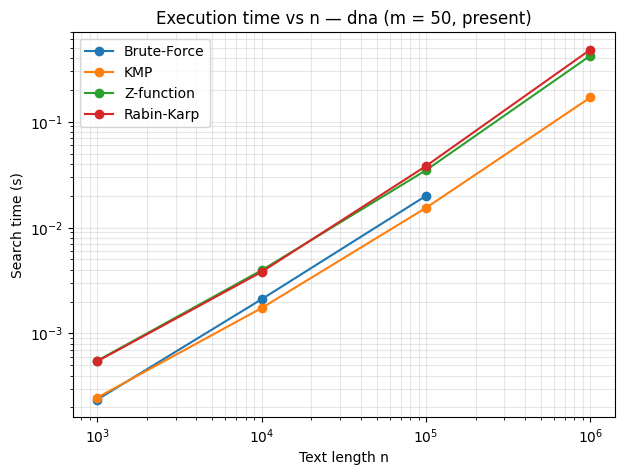

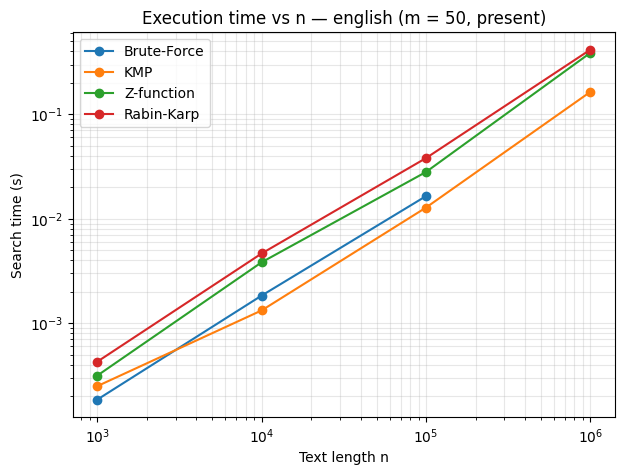

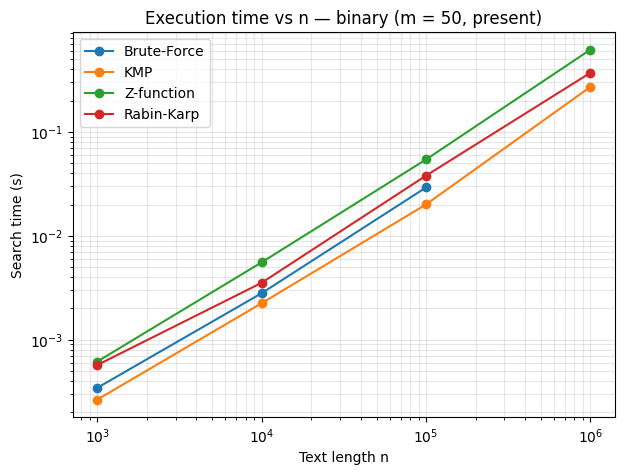

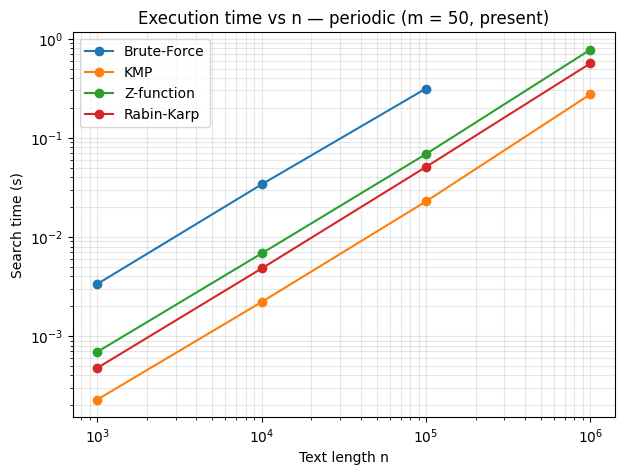

In [ ]:
ORDER = ["Brute-Force", "KMP", "Z-function", "Rabin-Karp"]


def plot_time_vs_n(corpus, m=50, kind="present"):
    subset = results[(results.corpus == corpus) & (results.m == m)
                     & (results.pattern_kind == kind)]
    if subset.empty:
        return
    fig, ax = plt.subplots()
    for algo in ORDER:
        series = subset[subset.algorithm == algo].groupby("n").time_mean.mean()
        if series.empty:
            continue
        ax.plot(series.index, series.values, marker="o", label=algo)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Text length n")
    ax.set_ylabel("Search time (s)")
    ax.set_title(f"Execution time vs n — {corpus} (m = {m}, {kind})")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.show()


for corpus in results.corpus.unique():
    plot_time_vs_n(corpus)

The second view isolates the alphabet-size effect by fixing n and m and comparing across corpora. It is the clearest view of how alphabet size changes the ranking.

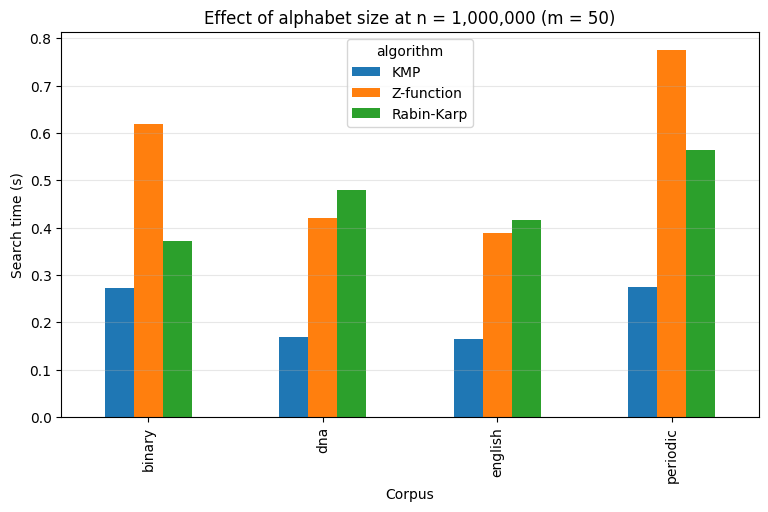

algorithm,KMP,Z-function,Rabin-Karp
corpus,,,
binary,0.271642,0.619976,0.371041
dna,0.169336,0.420221,0.478936
english,0.164264,0.388504,0.416544
periodic,0.275010,0.775255,0.564288


In [ ]:
def plot_alphabet_effect(n, m=50):
    subset = results[(results.n == n) & (results.m == m)
                     & (results.pattern_kind == "present")]
    if subset.empty:
        return
    pivot = subset.pivot_table(index="corpus", columns="algorithm",
                               values="time_mean", aggfunc="mean")
    pivot = pivot.reindex(columns=[a for a in ORDER if a in pivot.columns])
    ax = pivot.plot(kind="bar", figsize=(9, 5))
    ax.set_ylabel("Search time (s)")
    ax.set_xlabel("Corpus")
    ax.set_title(f"Effect of alphabet size at n = {n:,} (m = {m})")
    ax.grid(True, axis="y", alpha=0.3)
    plt.show()
    return pivot


plot_alphabet_effect(sorted(results.n.unique())[-1])

The third view drops wall-clock time in favour of character comparisons on degenerate patterns. Comparison counts are hardware-independent, which makes them the cleaner evidence when wall-clock time is noisy.

Note that the `comparisons` column is **not** comparable across all four algorithms. Rabin-Karp performs almost no character comparisons — it does `n` modular arithmetic operations instead, and only compares characters when a hash matches. Its comparison count therefore looks dramatically lower than KMP's while its wall-clock time is higher. The two metrics are therefore reported separately.

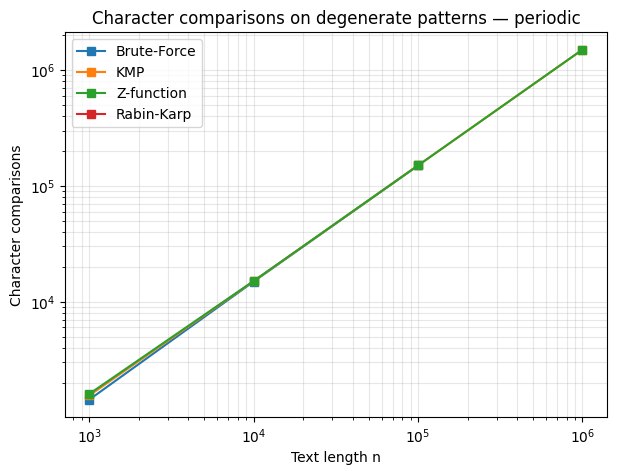

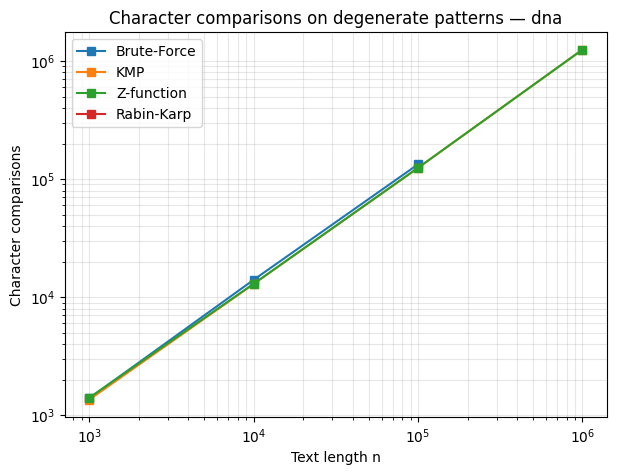

In [ ]:
def plot_comparisons(corpus, m=50, kind="degenerate"):
    subset = results[(results.corpus == corpus) & (results.m == m)
                     & (results.pattern_kind == kind)]
    if subset.empty:
        return
    fig, ax = plt.subplots()
    for algo in ORDER:
        series = subset[subset.algorithm == algo].groupby("n").comparisons.mean()
        if series.empty:
            continue
        ax.plot(series.index, series.values, marker="s", label=algo)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Text length n")
    ax.set_ylabel("Character comparisons")
    ax.set_title(f"Character comparisons on {kind} patterns — {corpus}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.show()


plot_comparisons("periodic")
plot_comparisons("dna")

### Rabin-Karp modulus sweep

The cost of Rabin-Karp is split between modular arithmetic on every window and character
verification whenever two hashes agree. Varying `q` while holding everything else fixed is what
separates the two.

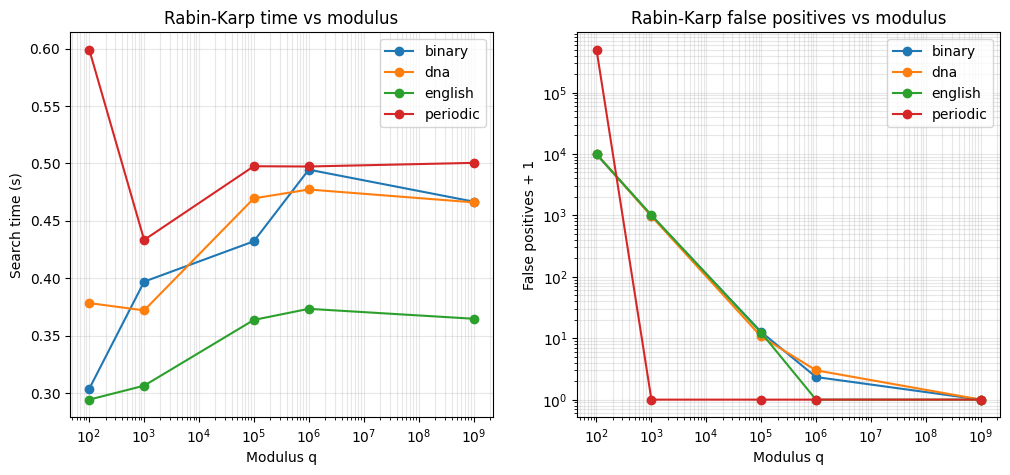

,corpus,modulus,time,false_positives
0,binary,101,0.303561,9879.000000
1,binary,1009,0.396940,988.666667
2,binary,100003,0.432101,11.666667
3,binary,1000003,0.494560,1.333333
4,binary,1000000007,0.466709,0.000000
5,dna,101,0.378266,10015.666667
6,dna,1009,0.371908,967.666667
7,dna,100003,0.469515,9.666667
8,dna,1000003,0.477258,2.000000
9,dna,1000000007,0.466051,0.000000


In [ ]:
MODULI = [101, 1009, 100003, 1_000_003, 1_000_000_007]


def run_modulus_sweep():
    rows = []
    for corpus_name, full_text in corpora.items():
        text = full_text[:min(len(full_text), MAX_N)]
        for entry in patterns[corpus_name]:
            if entry["kind"] != "present" or entry["m"] != 50:
                continue
            for q in MODULI:
                start = time.perf_counter()
                positions, stats = rabin_karp(text, entry["pattern"], modulus=q)
                rows.append({
                    "corpus": corpus_name,
                    "n": len(text),
                    "modulus": q,
                    "time": time.perf_counter() - start,
                    "matches": len(positions),
                    "hash_hits": stats["hash_hits"],
                    "false_positives": stats["false_positives"],
                })
    return pd.DataFrame(rows)


modulus_results = run_modulus_sweep()
modulus_results.to_csv("rabin_karp_modulus.csv", index=False)

grouped = modulus_results.groupby(["corpus", "modulus"]).agg(
    time=("time", "mean"), false_positives=("false_positives", "mean")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for corpus, part in grouped.groupby("corpus"):
    axes[0].plot(part.modulus, part.time, marker="o", label=corpus)
    axes[1].plot(part.modulus, part.false_positives + 1, marker="o", label=corpus)
axes[0].set_xscale("log")
axes[0].set_xlabel("Modulus q")
axes[0].set_ylabel("Search time (s)")
axes[0].set_title("Rabin-Karp time vs modulus")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Modulus q")
axes[1].set_ylabel("False positives + 1")
axes[1].set_title("Rabin-Karp false positives vs modulus")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.show()

grouped

### Reference baseline

Python's built-in `str.find` is implemented in C using a highly optimised hybrid algorithm. It outperforms the implementations above by a wide margin on most corpora, though not on the periodic worst case. Including it makes the point explicit that this benchmark measures algorithmic behaviour, not compiler or runtime optimisation.

In [ ]:
def builtin_find(t, p):
    positions = []
    start = 0
    while True:
        i = t.find(p, start)
        if i == -1:
            break
        positions.append(i)
        start = i + 1
    return positions, {"comparisons": 0}


baseline_rows = []
for corpus_name, full_text in corpora.items():
    text = full_text[:min(len(full_text), MAX_N)]
    entry = next(e for e in patterns[corpus_name] if e["kind"] == "present" and e["m"] == 50)
    for label, fn in [("str.find (C)", builtin_find), ("KMP (Python)", kmp_search),
                      ("Z-function (Python)", z_search)]:
        start = time.perf_counter()
        positions, _ = fn(text, entry["pattern"])
        baseline_rows.append({
            "corpus": corpus_name,
            "n": len(text),
            "implementation": label,
            "time": time.perf_counter() - start,
            "matches": len(positions),
        })

pd.DataFrame(baseline_rows).pivot_table(
    index="corpus", columns="implementation", values="time")

implementation,KMP (Python),Z-function (Python),str.find (C)
corpus,,,
binary,0.197259,0.704406,0.008586
dna,0.164261,0.366187,0.001542
english,0.133543,0.317451,0.000311
periodic,0.468053,1.367547,0.506042


### 3.4 Empirical discussion

The tables and figures above answer four questions. Each answer below cites the measurement that supports it.

In [ ]:
def summarise(corpus, kind="present", m=50):
    subset = results[(results.corpus == corpus) & (results.pattern_kind == kind)
                     & (results.m == m)]
    return subset.pivot_table(index="n", columns="algorithm", values="time_mean")


for corpus in results.corpus.unique():
    print(f"\n{corpus}")
    print(summarise(corpus).to_string())


dna
algorithm  Brute-Force       KMP  Rabin-Karp  Z-function
n                                                       
1000          0.000237  0.000248    0.000545    0.000552
10000         0.002103  0.001736    0.003810    0.003947
100000        0.019933  0.015346    0.038118    0.034779
1000000            NaN  0.169336    0.478936    0.420221

english
algorithm  Brute-Force       KMP  Rabin-Karp  Z-function
n                                                       
1000          0.000185  0.000249    0.000427    0.000314
10000         0.001836  0.001324    0.004647    0.003827
100000        0.016471  0.012792    0.038097    0.028043
1000000            NaN  0.164264    0.416544    0.388504

binary
algorithm  Brute-Force       KMP  Rabin-Karp  Z-function
n                                                       
1000          0.000344  0.000265    0.000569    0.000615
10000         0.002799  0.002243    0.003527    0.005551
100000        0.029185  0.020033    0.037940    0.054284
1000000  

**Do KMP and the Z-function hold Θ(n+m) across every corpus?**
Yes. Each tenfold increase in n raises their search time roughly tenfold on all four corpora, a log-log slope of about 1. At n = 10⁶ KMP takes 0.16–0.28 s, while the Z-function is 2.3–2.8 times slower, consistent with its Θ(n+m) auxiliary array against KMP's Θ(m).

**What actually drives Rabin-Karp's cost — collisions or arithmetic?**
Arithmetic. Raising the modulus from 101 to 1,000,000,007 cuts false positives from about 10,000 to 0, yet search time does not fall; it stays at 0.3–0.5 s. The cost is dominated by the rolling-hash update on every window, not by verifying collisions.

**How much does alphabet size matter?**
For KMP, small alphabets are slower: at n = 10⁶ it takes about 0.17 s on `dna` and `english` but 0.27 s on `binary` and `periodic`, because partial matches, and therefore fallbacks through the π-array, are more frequent when |Σ| = 2.

**How large is the Brute-Force penalty, and what controls it?**
On natural text it is small: Brute-Force is only 1.3–1.5 times slower than KMP. On periodic text the gap grows with pattern length rather than text length: 2× at m = 5, 14× at m = 50 and 139× at m = 500.

### Brute-Force penalty against pattern length

At a fixed `m`, both O(n·m) and O(n+m) grow linearly in n, so the ratio between Brute-Force and KMP
is a constant rather than a widening gap. What the ratio scales with is `m`. The cell below fixes n
at the largest size Brute-Force completed and plots the ratio against m.

Note the pattern kind: `present`, not `degenerate`. On text `abab...` a degenerate pattern `aaa...`
mismatches at the second character, so Brute-Force never enters its worst case. The worst case needs
a pattern that almost matches at every alignment — exactly what a pattern sampled from periodic text
does.

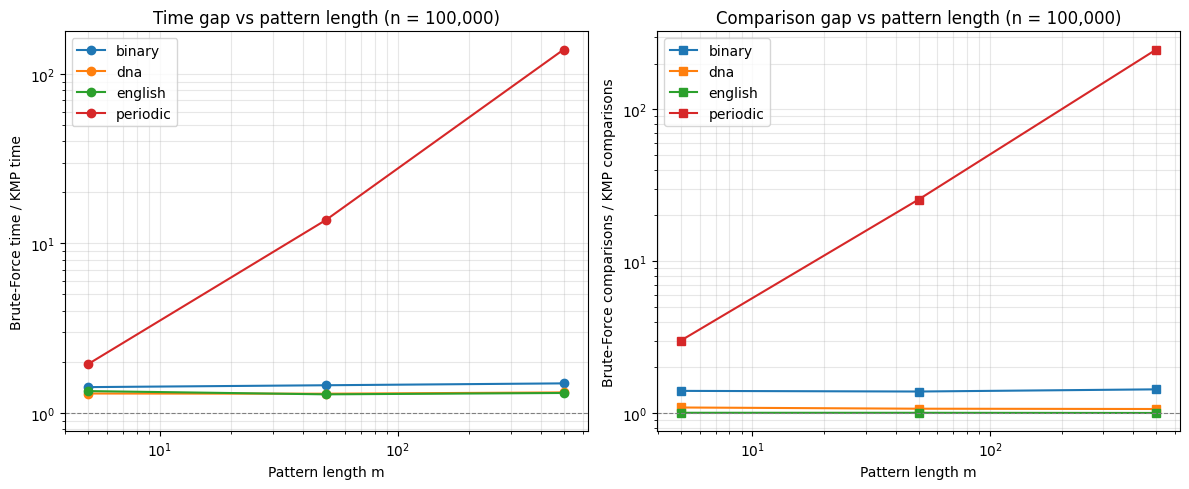

comparison_ratio                time_ratio               
m                     5      50      500        5      50      500
corpus                                                            
binary               1.40   1.39    1.43       1.42   1.46    1.49
dna                  1.09   1.07    1.06       1.30   1.30    1.32
english              1.00   1.00    1.00       1.35   1.29    1.31
periodic             3.00  25.48  248.01       1.95  13.76  139.32

In [ ]:
def brute_force_gap(kind="present", baseline="Brute-Force", reference="KMP"):
    n_fixed = results[results.algorithm == baseline].n.max()
    subset = results[(results.n == n_fixed) & (results.pattern_kind == kind)
                     & (results.algorithm.isin([baseline, reference]))]
    time_pivot = subset.pivot_table(index=["corpus", "m"], columns="algorithm",
                                    values="time_mean")
    comp_pivot = subset.pivot_table(index=["corpus", "m"], columns="algorithm",
                                    values="comparisons")
    gap = pd.DataFrame({
        "time_ratio": time_pivot[baseline] / time_pivot[reference],
        "comparison_ratio": comp_pivot[baseline] / comp_pivot[reference],
    }).reset_index()
    return n_fixed, gap


n_fixed, gap = brute_force_gap()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for corpus, part in gap.groupby("corpus"):
    part = part.sort_values("m")
    axes[0].plot(part.m, part.time_ratio, marker="o", label=corpus)
    axes[1].plot(part.m, part.comparison_ratio, marker="s", label=corpus)
axes[0].set_ylabel("Brute-Force time / KMP time")
axes[0].set_title(f"Time gap vs pattern length (n = {n_fixed:,})")
axes[1].set_ylabel("Brute-Force comparisons / KMP comparisons")
axes[1].set_title(f"Comparison gap vs pattern length (n = {n_fixed:,})")
for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Pattern length m")
    ax.axhline(1, color="grey", linewidth=0.8, linestyle="--")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

gap.pivot_table(index="corpus", columns="m",
                values=["time_ratio", "comparison_ratio"]).round(2)
